# Team 26 – Sleep, Study Habits, Lifestyle and GPA
**EDA and analysis notebook** (CS215 project). This notebook walks through the whole pipeline interactively; the same steps are in `scripts/` (run `python run_all.py` to regenerate every file in `results/`).

> **Data note.** The Kaggle *Student Lifestyle* file we use has **no screen-time column** (only study, sleep, physical activity, social, extracurricular hours, stress level and GPA). The screen-time hypotheses of the first proposal therefore cannot be tested; we test the revised hypotheses on the variables that exist.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seaborn as sns, statsmodels.api as sm, statsmodels.formula.api as smf
from IPython.display import Image, display
from utils import load_clean, HOUR_COLS, RESULTS_DIR
pd.set_option("display.width", 140)
%matplotlib inline

## 1. Load the cleaned data

In [2]:
df = load_clean()
print(df.shape)
df.head()

(2000, 9)


,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level,Stress_Level_Num
0,1,6.9,3.8,8.7,2.8,1.8,2.99,Moderate,2
1,2,5.3,3.5,8.0,4.2,3.0,2.75,Low,1
2,3,5.1,3.9,9.2,1.2,4.6,2.67,Low,1
3,4,6.5,2.1,7.2,1.7,6.5,2.88,Moderate,2
4,5,8.1,0.6,6.5,2.2,6.6,3.51,High,3


In [3]:
print((RESULTS_DIR / "preprocessing_log.txt").read_text())

Rows read: 2000
Completely empty rows removed: 0
Exact duplicate rows removed: 0
Duplicate Student_IDs removed: 0
Study_Hours_Per_Day: 0 missing -> median imputed
Sleep_Hours_Per_Day: 0 missing -> median imputed
Physical_Activity_Hours_Per_Day: 0 missing -> median imputed
Social_Hours_Per_Day: 0 missing -> median imputed
Extracurricular_Hours_Per_Day: 0 missing -> median imputed
GPA: 0 missing -> median imputed
Stress_Level: 0 missing -> mode imputed
Range checks: all passed
All five hour columns sum to exactly 24 h: True (=> perfect collinearity; Social hours is dropped from regressions)
Screen-time column present: False
Final rows: 2000, columns: 9



## 2. Exploratory analysis

In [4]:
df[["GPA", *HOUR_COLS, "Stress_Level_Num"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
GPA,2000.0,3.12,0.30,2.24,2.9,3.11,3.33,4.0
Study_Hours_Per_Day,2000.0,7.48,1.42,5.00,6.3,7.40,8.70,10.0
Sleep_Hours_Per_Day,2000.0,7.50,1.46,5.00,6.2,7.50,8.80,10.0
Physical_Activity_Hours_Per_Day,2000.0,4.33,2.51,0.00,2.4,4.10,6.10,13.0
Social_Hours_Per_Day,2000.0,2.70,1.69,0.00,1.2,2.60,4.10,6.0
Extracurricular_Hours_Per_Day,2000.0,1.99,1.16,0.00,1.0,2.00,3.00,4.0
Stress_Level_Num,2000.0,2.37,0.73,1.00,2.0,3.00,3.00,3.0


**Key structural fact:** the five time-use variables add up to exactly 24 hours for every student, so they are perfectly collinear with an intercept. One of them (Social) must be left out of every regression.

In [5]:
s = df[HOUR_COLS].sum(axis=1)
print("min/max of the 5-hour sum:", s.min().round(6), s.max().round(6))
X_bad = sm.add_constant(df[HOUR_COLS])
print("rank:", np.linalg.matrix_rank(X_bad.values), "of", X_bad.shape[1], "columns -> singular")

min/max of the 5-hour sum: 24.0 24.0
rank: 5 of 6 columns -> singular


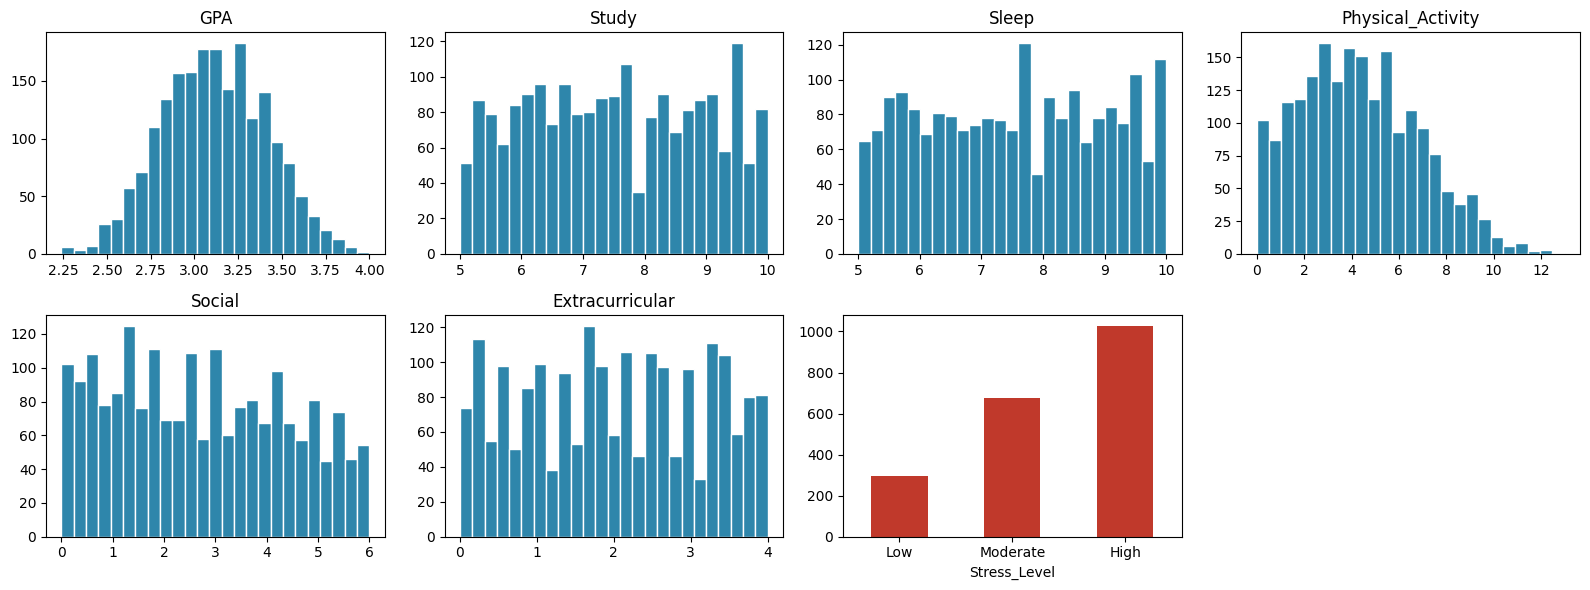

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.ravel(), ["GPA", *HOUR_COLS]):
    ax.hist(df[c], bins=25, color="#2e86ab", edgecolor="white"); ax.set_title(c.replace("_Hours_Per_Day", ""))
df["Stress_Level"].value_counts().reindex(["Low","Moderate","High"]).plot.bar(ax=axes.ravel()[6], rot=0, color="#c0392b")
axes.ravel()[7].axis("off"); plt.tight_layout(); plt.show()

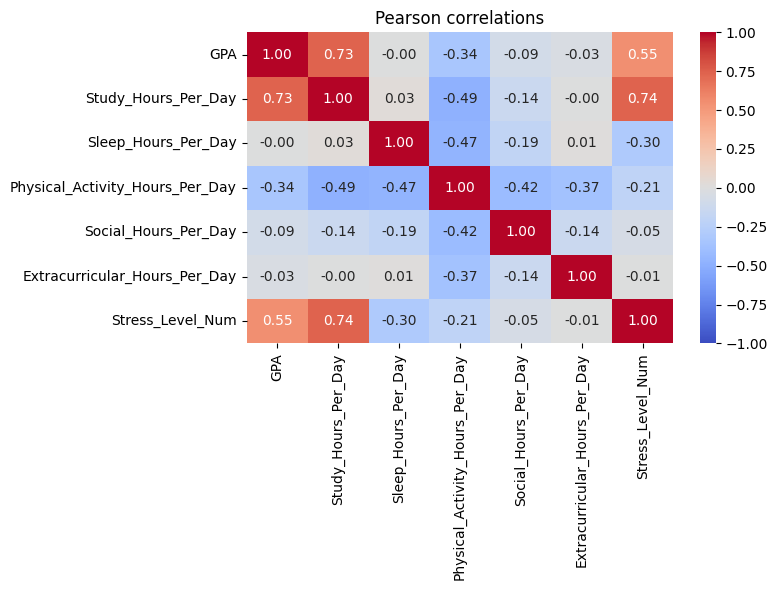

In [7]:
corr = df[["GPA", *HOUR_COLS, "Stress_Level_Num"]].corr()
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Pearson correlations"); plt.tight_layout(); plt.show()

In [8]:
df.groupby("Stress_Level")[["GPA", "Study_Hours_Per_Day", "Sleep_Hours_Per_Day", "Physical_Activity_Hours_Per_Day"]].mean().round(2)

,GPA,Study_Hours_Per_Day,Sleep_Hours_Per_Day,Physical_Activity_Hours_Per_Day
Stress_Level,,,,
High,3.26,8.39,7.05,3.96
Low,2.82,5.47,8.06,5.58
Moderate,3.02,6.97,7.95,4.34


GPA is almost entirely linked to **study hours** (r = 0.73). Sleep has r ≈ 0 with GPA. Physical activity and stress *look* related to GPA, but both are strongly correlated with study hours (r = −0.49 and +0.74), which is what we check next.

## 3. Regression models

In [9]:
d = df.rename(columns={"Study_Hours_Per_Day":"Study","Sleep_Hours_Per_Day":"Sleep","Physical_Activity_Hours_Per_Day":"Phys",
                       "Social_Hours_Per_Day":"Social","Extracurricular_Hours_Per_Day":"Extra","Stress_Level_Num":"Stress"})
m_study = smf.ols("GPA ~ Study", d).fit()
m_sleep = smf.ols("GPA ~ Sleep", d).fit()
m_int   = smf.ols("GPA ~ Study * Sleep", d).fit()
m_full  = smf.ols("GPA ~ Study + Sleep + Phys + Extra + Stress", d).fit()   # Social = reference
pd.DataFrame({n: {"R2": m.rsquared, "adj_R2": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic}
              for n, m in {"Study only": m_study, "Sleep only": m_sleep, "Study x Sleep": m_int, "Full": m_full}.items()}).T.round(4)

,R2,adj_R2,AIC,BIC
Study only,0.5394,0.5392,-705.5010,-694.2992
Sleep only,0.0000,-0.0005,845.1007,856.3025
Study x Sleep,0.5408,0.5401,-707.2236,-684.8200
Full,0.5410,0.5398,-704.1325,-670.5271


In [10]:
print(m_full.summary().tables[1])
f, p, k = m_full.compare_f_test(m_study)
print(f"\nFull vs study-only: F = {f:.2f}, p = {p:.3f}, df diff = {int(k)}  ->  extra variables add nothing")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.0387      0.061     33.343      0.000       1.919       2.159
Study          0.1530      0.006     26.977      0.000       0.142       0.164
Sleep         -0.0058      0.004     -1.414      0.157      -0.014       0.002
Phys          -0.0013      0.003     -0.471      0.638      -0.007       0.004
Extra         -0.0088      0.005     -1.953      0.051      -0.018    3.49e-05
Stress         0.0002      0.010      0.020      0.984      -0.020       0.021

Full vs study-only: F = 1.66, p = 0.158, df diff = 4  ->  extra variables add nothing


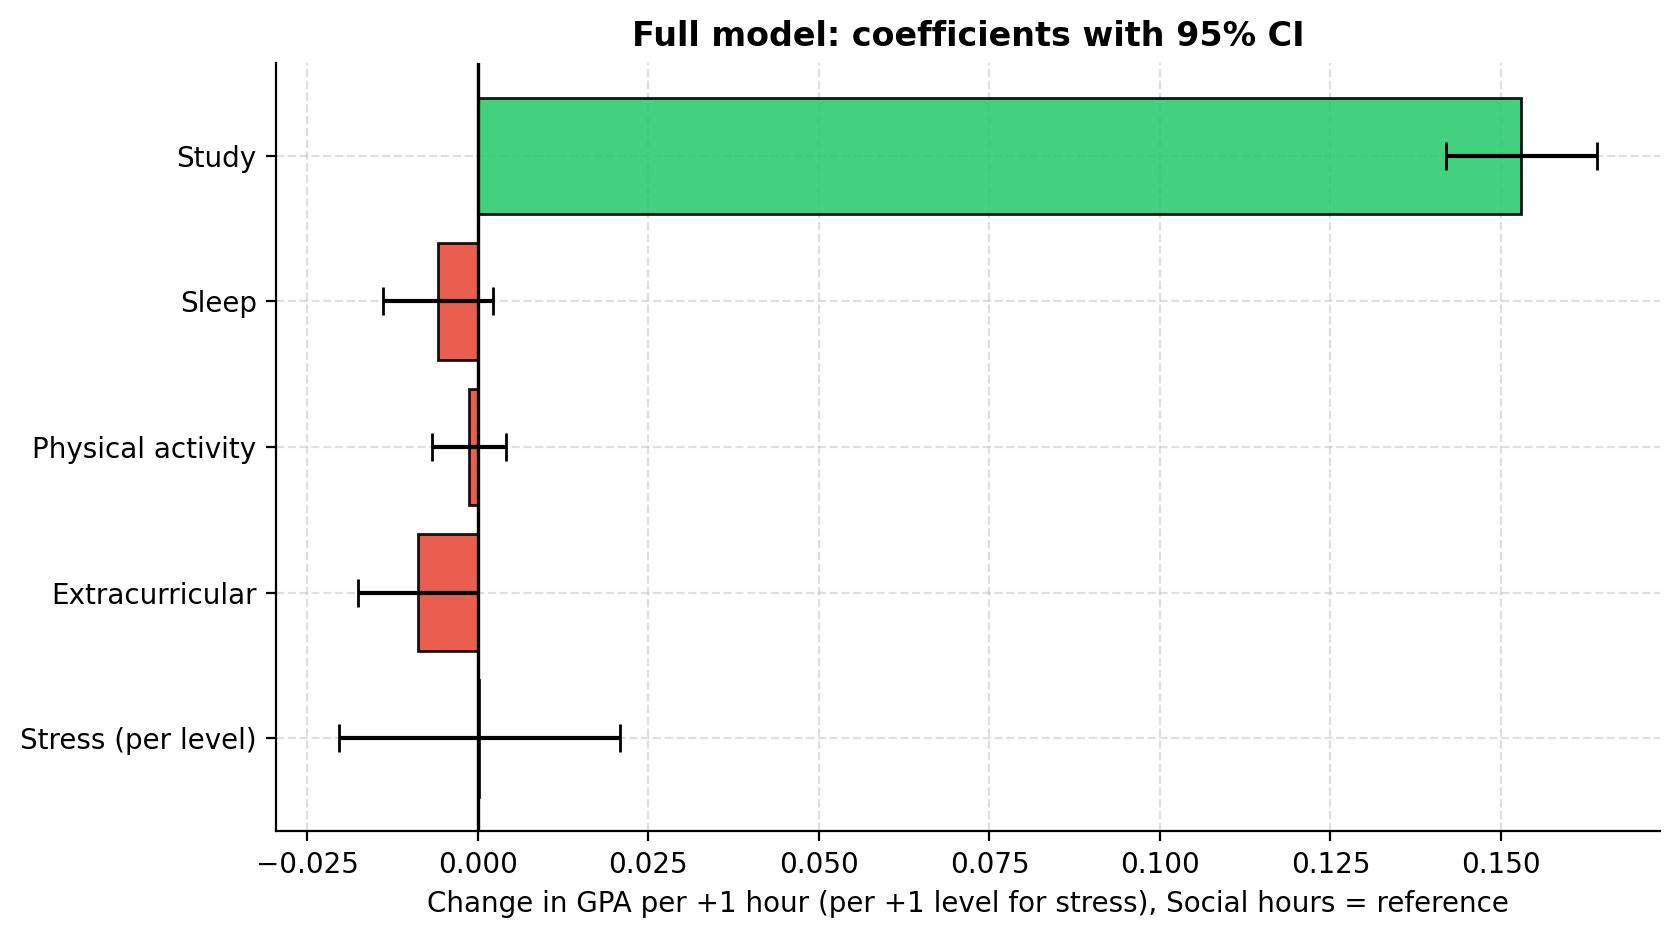

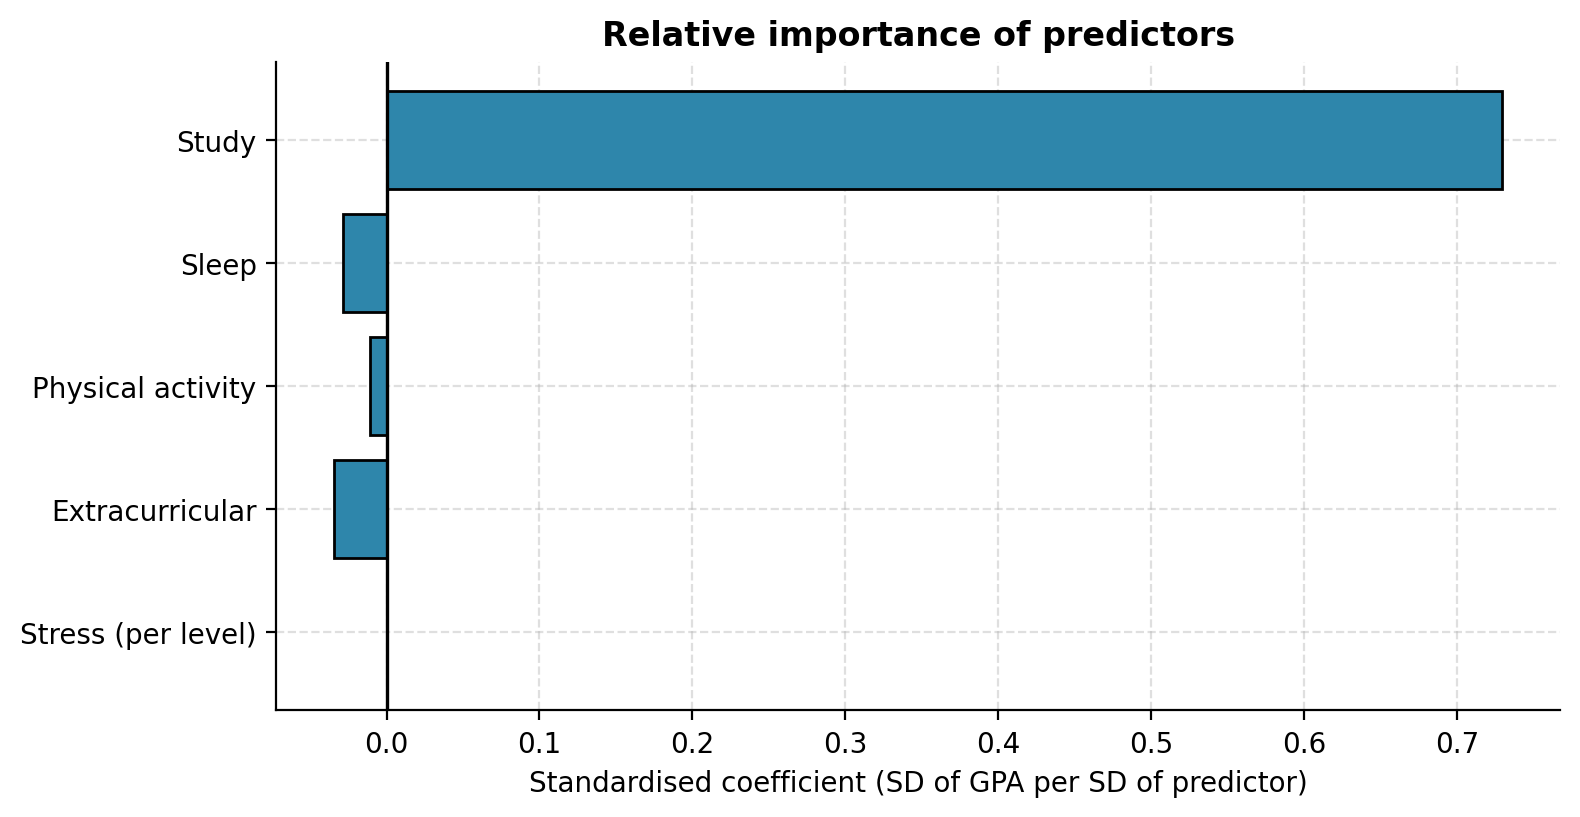

In [11]:
for name in ["regression_coefficients.png", "standardized_coefficients.png"]:
    display(Image(str(RESULTS_DIR / name), width=600))

## 4. Hypothesis tests

In [12]:
print((RESULTS_DIR / "validation_metrics.txt").read_text())

Observations: 2000
Social hours is the reference (the five hour columns sum to 24).

=== H1: study and sleep both significantly positive? ===
Study  (alone):    b = +0.1541, p = <1e-16
Sleep  (alone):    b = -0.0009, p = 0.848
Study  (| sleep):  b = +0.1542, p = <1e-16
Sleep  (| study):  b = -0.0049, p = 0.115
Verdict: NOT SUPPORTED (study yes, sleep no)

=== H2: do social time / low physical activity hurt GPA once study is controlled? ===
Phys    unadjusted: b = -0.0405 (p = <1e-16)   | adjusted for study: b = +0.0027 (p = 0.19)
Social  unadjusted: b = -0.0152 (p = 0.000125)   | adjusted for study: b = +0.0028 (p = 0.301)
Joint F-test (Phys + Social | Study): F = 3.14, p = 0.0434; b_phys = +0.0057, b_social = +0.0070
Verdict: NOT SUPPORTED - the raw negative association of physical activity (r = -0.34) is explained by study hours. After adjustment the effects are ~0 and, where the joint test is borderline significant, of the OPPOSITE sign and < 0.01 GPA per hour.

=== H3: Study x Slee

## 5. Conclusions
* **Study hours** are the only meaningful predictor of GPA (≈ +0.15 GPA per extra hour, R² ≈ 0.54).
* **Sleep** has no detectable relationship with GPA, alone or after controlling for study (H1 only half supported).
* Physical activity, social time and stress look related to GPA on their own, but the association disappears once study hours are controlled (H2 not supported). Stress is mostly a consequence of study load.
* Study × Sleep interaction is borderline (p = 0.07) and practically negligible (H3 not supported).
* The full model does not beat study hours alone (H4 not supported).
* Limitations: no screen-time variable; observational and apparently synthetic data (strikingly clean, linear relationships).